# Week 7 — Exercise 3 (optional): De novo peptide sequencing

**27200 Data-driven Bioengineering**

> **Optional.** Do this exercise in class if there is time, or at home. In the lecture we read a real
> spectrum by hand; this notebook lets you practise on a simulated one, and then compares that
> reasoning with an algorithm and with a deep learning model.

A tandem mass spectrum (MS/MS) is a list of fragment masses. The peptide that produced it is written
in the gaps between those masses. In this exercise you read that sequence three ways:

| Part | How | Time |
|---|---|---|
| A | **By hand**, from a simulated spectrum | 20 min |
| B | **With an algorithm** that does the same reasoning automatically | 10 min |
| C | **With a deep learning model**, InstaNovo, on 100 real HeLa spectra | 15 min |

The real spectra come from one LC-MS/MS run of a HeLa cell digest
([PXD045495](https://www.ebi.ac.uk/pride/archive/projects/PXD045495), Orbitrap Eclipse, HCD).

> **Before you start:** *Runtime → Change runtime type → T4 GPU*. Part C needs it; A and B do not.
> Then run the install cell below. It takes about 5 minutes and restarts the runtime at the end.
> The restart is expected. Read Part A while it installs.

## Setup

In [ ]:
#@title Install InstaNovo (about 5 min, then the runtime restarts)
# Skips itself if InstaNovo is already installed, so it is safe to run again.
try:
    import instanovo  # noqa: F401
    print("InstaNovo is already installed. Continue with the next cell.")
except ImportError:
    # Keep Colab's own GPU build of PyTorch and add InstaNovo on top of it.
    !pip install -q --prefer-binary --upgrade-strategy only-if-needed "instanovo[cu126]==1.2.2" "polars==1.35.2"
    print("Installed. The runtime will now restart; this is expected. Then continue with the next cell.")
    get_ipython().kernel.do_shutdown(restart=True)

In [2]:
import os, re, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/UadKLab/27200_Data-Driven-Bioengineering/main/weeks/week07_proteomics/data/"

def fetch(name):
    '''Download a course data file once; afterwards use the local copy.'''
    if not os.path.exists(name):
        urllib.request.urlretrieve(BASE + name, name)
    return name

# The files used in this notebook: a simulated spectrum (Part A), 100 real HeLa spectra with their
# database-search answers (Parts B and C), and InstaNovo predictions to fall back on if needed
for f in ["mystery_spectrum.csv", "mystery_real_spectrum.csv", "hela_100.mgf",
          "hela_100_reference.csv", "hela_100_instanovo_preds.csv"]:
    fetch(f)
print("data ready")

data ready


---
# Part A — Reading a spectrum by hand

When a peptide is fragmented, it breaks mostly at the peptide bonds. Each break gives two pieces:

- a **b ion**, the N-terminal piece: the first *i* residues
- a **y ion**, the C-terminal piece: the last *i* residues, plus a water

So the **b ions form a ladder** from the N-terminus and the **y ions form a ladder** from the
C-terminus. Two neighbouring rungs of a ladder differ by exactly one amino acid, and every amino
acid has a known mass. Reading a spectrum is reading those differences.

> **Terms**
>
> - **m/z** — mass divided by charge. All fragments here are singly charged, so m/z is the mass
>   plus one proton (1.00728 Da).
> - **Precursor** — the intact peptide ion that was selected for fragmentation.
> - **Residue mass** — the mass an amino acid adds to a peptide chain (the free amino acid minus
>   one water).
> - **Monoisotopic** — the mass using only the most common isotope of each element (¹²C, ¹H, ¹⁴N, ¹⁶O).

In [3]:
# The masses and functions used throughout this notebook.

# ---------------------------------------------------------------- masses
PROTON = 1.007276
H2O = 18.010565
NH3 = 17.026549
AA = {  # monoisotopic residue masses; C is carbamidomethylated (the usual fixed modification)
    "G": 57.02146, "A": 71.03711, "S": 87.03203, "P": 97.05276, "V": 99.06841,
    "T": 101.04768, "C": 160.03065, "L": 113.08406, "I": 113.08406, "N": 114.04293,
    "D": 115.02694, "Q": 128.05858, "K": 128.09496, "E": 129.04259, "M": 131.04049,
    "H": 137.05891, "F": 147.06841, "R": 156.10111, "Y": 163.06333, "W": 186.07931,
}


def peptide_mass(seq):
    """Neutral monoisotopic mass of a peptide: residues + one water."""
    return sum(AA[a] for a in seq) + H2O


def precursor_mz(seq, z):
    return (peptide_mass(seq) + z * PROTON) / z


def fragment_ions(seq):
    """Singly charged b and y ions. b_i = first i residues, y_i = last i residues."""
    b = np.cumsum([AA[a] for a in seq[:-1]]) + PROTON
    y = np.cumsum([AA[a] for a in seq[::-1][:-1]]) + H2O + PROTON
    return b, y



# The residue masses, lightest first. Keep this table open while you work.
print(pd.Series(AA).drop("I").sort_values().round(5).to_string())
print("\nI and L have identical mass (113.08406) and cannot be told apart this way.")

G     57.02146
A     71.03711
S     87.03203
P     97.05276
V     99.06841
T    101.04768
L    113.08406
N    114.04293
D    115.02694
Q    128.05858
K    128.09496
E    129.04259
M    131.04049
H    137.05891
F    147.06841
R    156.10111
C    160.03065
Y    163.06333
W    186.07931

I and L have identical mass (113.08406) and cannot be told apart this way.


In [4]:
# A worked example: the b and y ladders of a short peptide.
example = "PEPTIDE"
b, y = fragment_ions(example)
ladder = pd.DataFrame({
    "b ion":   [example[:i+1] for i in range(len(example)-1)],
    "b m/z":   b.round(4),
    "y ion":   [example[-(i+1):] for i in range(len(example)-1)],
    "y m/z":   y.round(4),
})
print(f"{example}: neutral mass {peptide_mass(example):.4f}, precursor m/z at 2+ = {precursor_mz(example, 2):.4f}\n")
print(ladder.to_string(index=False))

PEPTIDE: neutral mass 799.3599, precursor m/z at 2+ = 400.6872

 b ion    b m/z  y ion    y m/z
     P  98.0600      E 148.0604
    PE 227.1026     DE 263.0874
   PEP 324.1554    IDE 376.1714
  PEPT 425.2031   TIDE 477.2191
 PEPTI 538.2871  PTIDE 574.2719
PEPTID 653.3141 EPTIDE 703.3145


Look at the table: `b2 − b1` is the mass of E, `y2 − y1` is the mass of D. Also, `b1 + y6` (the two
pieces from the same break) always adds up to the precursor mass plus one extra proton. Those two
facts are everything you need.

## The mystery spectrum

Below is an MS/MS spectrum of a real HeLa peptide, simulated to look like real data: some fragments
are missing, y ions are stronger than b ions (typical for this fragmentation method), there are a few
peaks from water/ammonia losses, a scattering of noise peaks, and a few ppm of mass error.

**Precursor: m/z 473.27944, charge 2+.** The peptide is tryptic, so it ends in K or R.

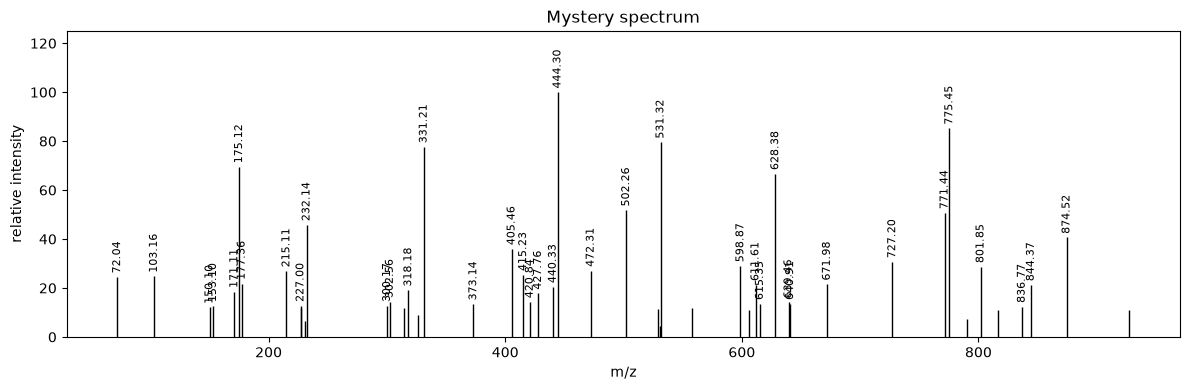

      mz  intensity
 72.0439      24.47
103.1570      24.75
150.0997      12.03
153.1023      12.76
171.1113      18.52
175.1192      69.46
177.3632      21.83
215.1138      26.95
226.9999      12.82
227.4984      11.77
230.6038       6.52
232.1380      45.82
300.1691      12.76
302.5625      14.39
314.1831      11.92
318.1807      19.08
326.2706       8.96
331.2073      77.63
373.1441      13.42
405.4639      36.00
415.2343      25.43
420.8444      14.33
427.7644      17.83
440.3317      20.48
444.2979     100.00
472.3076      27.13
502.2639      51.83
529.3420      11.57
531.0547       4.37
531.3232      79.53
557.5660      11.86
598.8676      29.06
605.7978      11.16
611.6058      21.36
615.3507      13.61
628.3792      66.70
639.4559      14.23
640.9135      13.61
671.9773      21.55
727.1984      30.68
771.4391      50.71
775.4454      85.22
790.2609       7.40
801.8492      28.69
816.3068      10.93
836.7660      12.42
844.3671      21.28
874.5176      40.63
927.5815      11.06


In [5]:
spec = pd.read_csv("mystery_spectrum.csv")      # two columns: m/z and relative intensity
PREC_MZ, Z = 473.27944, 2                        # precursor m/z and charge (given above)

fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(spec.mz, 0, spec.intensity, color="k", lw=1)    # one vertical line per peak
for r in spec[spec.intensity > 12].itertuples():          # label the bigger peaks with their m/z
    ax.text(r.mz, r.intensity + 1.5, f"{r.mz:.2f}", rotation=90, ha="center", va="bottom", fontsize=8)
ax.set(xlabel="m/z", ylabel="relative intensity", ylim=(0, 125), title="Mystery spectrum")
plt.tight_layout(); plt.show()

# The full peak list, sorted by m/z. Strong peaks are more likely to be real b or y ions.
print(spec.round(4).to_string(index=False))

## How to read it

1. **Work out the peptide mass.** `M = (precursor m/z − 1.00728) × charge`. The residues add up to
   `M − 18.01056` (the water).
2. **Find y1.** A tryptic peptide ends in K or R, so y1 is at **147.113** (K) or **175.119** (R).
   Only one of those is in the spectrum.
3. **Climb the y ladder.** Look for a peak that is exactly one residue mass above y1. That residue is
   the second-last amino acid. Repeat from the new peak. Use `gap()` below to name the residue between
   two peaks.
4. **When a rung is missing**, use the b ladder instead. A b ion and a y ion from the same break add up
   to `M + 2 × 1.00728`. `complement()` gives you the partner of any peak.
5. **Check your answer** with `check_answer()`. It tells you whether the total mass fits and draws your
   sequence's fragments against the spectrum.

Write down the sequence as you go, from the C-terminus backwards.

In [6]:
def gap(mz1, mz2, tol=0.02):
    '''Which amino acid (or pair) fits the mass difference between two peaks?'''
    d = abs(mz2 - mz1)                                    # the mass difference between the two peaks
    hits = [a for a, m in AA.items() if a != "I" and abs(d - m) <= tol]   # residues that fit it
    pairs = sorted({"".join(sorted(a + b)) for a, ma in AA.items() for b, mb in AA.items()
                    if a != "I" and b != "I" and abs(d - ma - mb) <= tol})
    msg = f"difference {d:.4f}: "
    msg += (", ".join(hits) if hits else "no single residue")
    if not hits and pairs:
        msg += f"  (two residues: {', '.join(pairs)})"
    print(msg)

def complement(mz):
    '''The m/z of the fragment from the other side of the same break.'''
    M = (PREC_MZ - PROTON) * Z                            # neutral peptide mass
    partner = M + 2 * PROTON - mz                         # b + y from the same break = M + 2 protons
    print(f"the partner of {mz:.4f} would be at {partner:.4f}")
    return partner

M = (PREC_MZ - PROTON) * Z
print(f"peptide mass M = {M:.4f} Da; residues add up to {M - H2O:.4f} Da")
gap(175.119, 232.14)        # an example of how to use it

peptide mass M = 944.5443 Da; residues add up to 926.5338 Da
difference 57.0210: G


Not quite. Your sequence's precursor m/z is off by +11533.1 ppm.


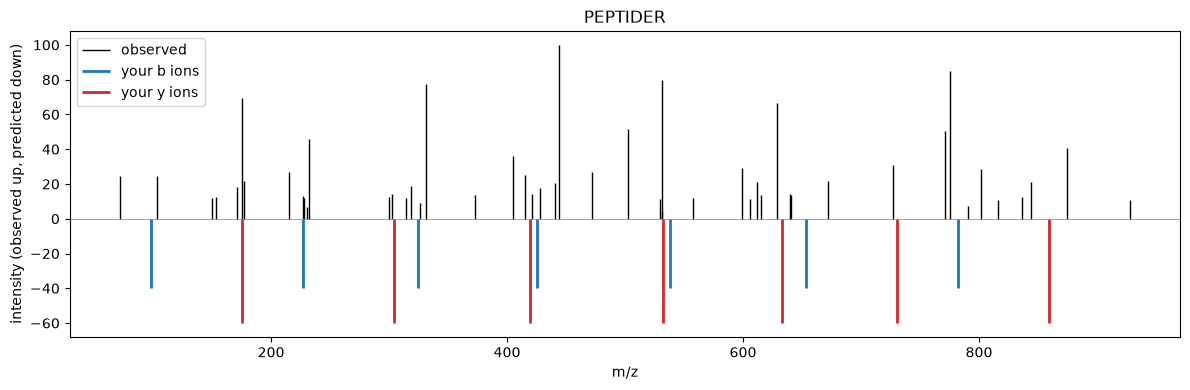

In [7]:
def check_answer(seq):
    '''Compare your sequence with the answer, and draw its fragments on the spectrum.'''
    seq = seq.strip().upper()
    guess = seq.replace("I", "L")                        # I and L weigh the same: count them as one
    # compare a fingerprint (hash) of your answer with the fingerprint of the right one
    ok = hashlib.sha256(guess.encode()).hexdigest() == "8e83f795b3a756bbdf0e5d5bf91c1d871470fddf0e082b6eb33e0cc2fc35fb56"
    err = (precursor_mz(seq, Z) - PREC_MZ) / PREC_MZ * 1e6
    print("Correct!" if ok else "Not quite.", f"Your sequence's precursor m/z is off by {err:+.1f} ppm.")
    b, y = fragment_ions(seq)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.vlines(spec.mz, 0, spec.intensity, color="k", lw=1, label="observed")
    ax.vlines(b, 0, -40, color="tab:blue", lw=2, label="your b ions")
    ax.vlines(y, 0, -60, color="tab:red", lw=2, label="your y ions")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set(xlabel="m/z", ylabel="intensity (observed up, predicted down)", title=seq)
    ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

check_answer("PEPTIDER")     # replace with your answer

**Question 3.1** Which positions in your sequence were you least sure about, and why? Could you tell
isoleucine from leucine?

**Question 3.2** Glycine + glycine weighs 114.04292 Da. Asparagine weighs 114.04293 Da. Alanine +
glycine weighs 128.05857 Da, glutamine 128.05858 Da. What would happen to your reading if the peak
between two such residues were missing?

Once you have solved it, run the cell below. It fetches the **real** spectrum of the same peptide
straight from the PRIDE archive, using its *universal spectrum identifier* (USI).

fetched from PRIDE: mzspec:PXD045495:11052020_HeLa09:scan:67375


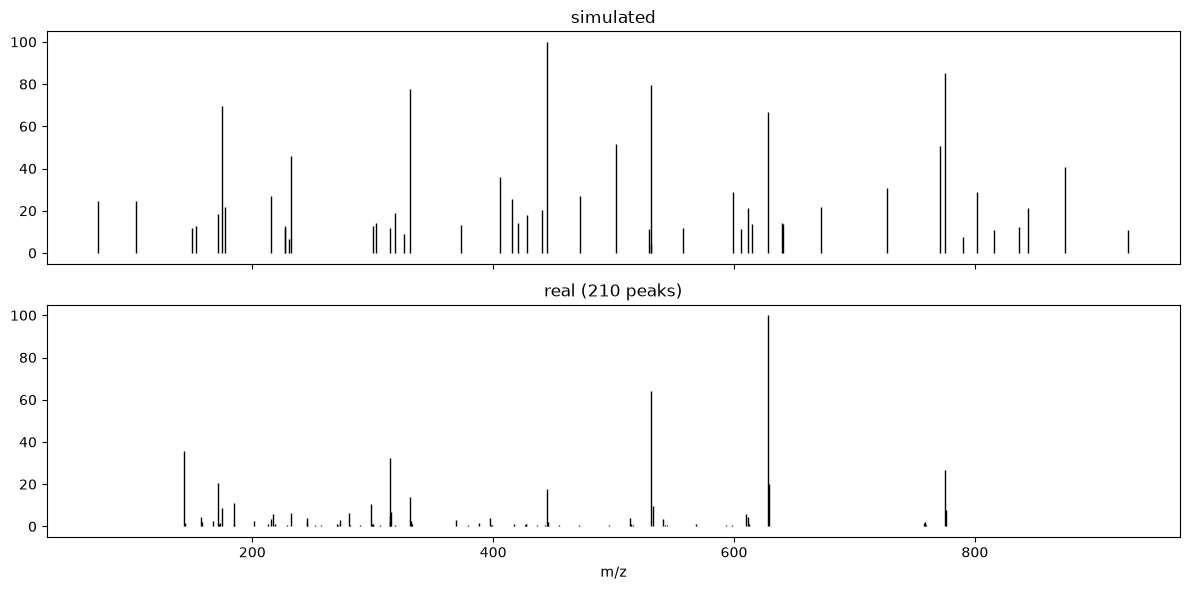

In [8]:
# A USI points to one spectrum in one file of one public dataset.
usi = "mzspec:PXD045495:11052020_HeLa09:scan:67375"
try:
    import requests
    r = requests.get("https://www.ebi.ac.uk/pride/proxi/archive/v0.1/spectra",
                     params={"resultType": "full", "usi": usi}, timeout=30)
    j = r.json()[0]
    real = pd.DataFrame({"mz": np.array(j["mzs"], float), "intensity": np.array(j["intensities"], float)})
    print("fetched from PRIDE:", usi)
except Exception:
    real = pd.read_csv("mystery_real_spectrum.csv")          # a local copy, in case PRIDE is slow
    print("PRIDE did not answer; using the local copy of", usi)

real["intensity"] = real.intensity / real.intensity.max() * 100
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].vlines(spec.mz, 0, spec.intensity, color="k", lw=1); ax[0].set_title("simulated")
ax[1].vlines(real.mz, 0, real.intensity, color="k", lw=1); ax[1].set_title(f"real ({len(real)} peaks)")
ax[1].set_xlabel("m/z"); plt.tight_layout(); plt.show()

**Question 3.3** How does the real spectrum differ from the simulated one? Would you have been able
to read it by hand?

---
# Part B — An algorithm that reads spectra

What you just did can be written as an algorithm. The idea, from the late 1990s, is the **spectrum
graph**:

1. Every peak might be a b ion or a y ion. Convert both readings into a **prefix mass** — the summed
   mass of the first residues. A b ion gives it directly; a y ion gives it by subtracting from the
   total.
2. Make every prefix mass a **node**. Add a start node at 0 and an end node at the full residue mass.
3. Join two nodes with an **edge** when their difference is the mass of one amino acid (or of two, to
   jump over a missing fragment).
4. The peptide is the **best path from start to end**. Because nodes are sorted by mass, there are no
   cycles, and **dynamic programming** finds the best path exactly: for each node, remember the best
   score of any path that reaches it, and where it came from.

In [9]:
def denovo_dp(mz, intensity, prec_mz, z, tol=0.02, max_gap=2, gap_penalty=1.0):
    """De novo sequencing as a longest-path problem.

    1. Every peak could be a b ion or a y ion. Convert both readings into a *prefix mass*:
       the summed mass of the first residues of the peptide.
    2. Those prefix masses are the nodes of a graph, plus 0 (nothing) and the full residue
       mass (everything). Two nodes are joined when their difference is the mass of one
       amino acid, or of two (to jump over a missing fragment).
    3. The sequence is the best-scoring path from 0 to the full mass. Nodes are sorted by
       mass, so the graph has no cycles and dynamic programming finds that path exactly.
    """
    M = (prec_mz - PROTON) * z                  # neutral peptide mass
    R = M - H2O                                 # summed residue mass
    w = np.log1p(np.asarray(intensity, float))  # peak score: log intensity

    cand = [(0.0, 0.0), (R, 0.0)]
    for m, s in zip(mz, w):
        pb = m - PROTON                         # if the peak is b: prefix directly
        py = R - (m - PROTON - H2O)             # if the peak is y: complement of the suffix
        for p in (pb, py):
            if tol < p < R - tol:
                cand.append((p, s))
    cand.sort()
    nodes, scores = [], []                      # merge nodes closer than tol (b and y agreeing)
    for p, s in cand:
        if nodes and p - nodes[-1] < tol:
            scores[-1] += s
        else:
            nodes.append(p); scores.append(s)
    nodes, scores = np.array(nodes), np.array(scores)

    single = {m: a for a, m in AA.items() if a != "I"}          # I and L are identical in mass
    pairs = {}
    if max_gap >= 2:
        for ma, a in single.items():
            for mb, b in single.items():
                pairs.setdefault(round(ma + mb, 3), set()).add("".join(sorted(a + b)))

    n = len(nodes)
    best = np.full(n, -np.inf); best[0] = 0.0
    back = [None] * n
    for j in range(1, n):
        for i in range(j):
            if best[i] == -np.inf:
                continue
            d = nodes[j] - nodes[i]
            if d > 2 * 186.08 + tol:            # no two residues are heavier than W+W
                continue
            step, pen = None, 0.0
            for m, a in single.items():
                if abs(d - m) <= tol:
                    step = a; break
            if step is None:
                for m, combo in pairs.items():
                    if abs(d - m) <= tol:
                        step = "(" + "|".join(sorted(combo)) + ")"; pen = gap_penalty; break
            if step is None:
                continue
            sc = best[i] + scores[j] - pen
            if sc > best[j]:
                best[j] = sc; back[j] = (i, step)
    end = int(np.argmin(np.abs(nodes - R)))
    if best[end] == -np.inf:
        return None, -np.inf
    seq, k = [], end
    while back[k] is not None:
        i, step = back[k]
        seq.append(step); k = i
    return "".join(reversed(seq)), float(best[end])

In [10]:
seq, score = denovo_dp(spec.mz.values, spec.intensity.values, PREC_MZ, Z)
print("the algorithm reads the mystery spectrum as:", seq)

the algorithm reads the mystery spectrum as: AVFPSLVGR


Parentheses mark a place where the algorithm had to jump over a missing fragment: `(AV|GL)` means
"two residues weighing 170.106 Da", which fits both A+V and G+L.

Now try it on real spectra. We use 60 spectra from the HeLa run that a database search (MSGF+)
identified with confidence, so we know the right answer.

In [11]:
from pyteomics import mgf

def with_2plus(mz, inten, z):
    '''For precursors of charge 3 and up, a fragment can carry two charges. Add the singly
    charged equivalent of every peak so the graph can use them too.'''
    if z < 3:
        return mz, inten
    m1 = 2 * mz - PROTON
    return np.concatenate([mz, m1]), np.concatenate([inten, inten * 0.5])

def residue_recall(pred, truth, tol=0.05):
    '''Fraction of the true residue boundaries that the prediction also has.'''
    def masses(s):
        out = []
        for t in re.findall(r"\([^)]*\)|[A-Z]", s or ""):
            out.append(sum(AA[a] for a in t[1:-1].split("|")[0]) if t[0] == "(" else AA[t])
        return np.cumsum(out)
    true_b = np.cumsum([AA[a] for a in truth]); pred_b = masses(pred)
    return float(np.mean([np.any(np.abs(pred_b - m) < tol) for m in true_b]))

ref = pd.read_csv("hela_100_reference.csv").set_index("scan")
rows = []
for s in mgf.read("hela_100.mgf"):
    scan = int(s["params"]["scans"]); truth = ref.loc[scan, "msgf_peptide"]
    if pd.isna(truth) or "[" in truth:           # skip unidentified and modified peptides
        continue
    z = int(s["params"]["charge"][0]); pmz = s["params"]["pepmass"][0]
    mz, inten = s["m/z array"], s["intensity array"]
    top = np.argsort(inten)[-100:]               # the 100 strongest peaks
    mz, inten = with_2plus(mz[top], inten[top], z)
    pred, _ = denovo_dp(mz, inten, pmz, z)
    rows.append(dict(scan=scan, charge=z, truth=truth, prediction=pred,
                     exact=(pred or "").replace("I", "L") == truth.replace("I", "L"),
                     residue_recall=residue_recall(pred, truth.replace("I", "L"))))
dp = pd.DataFrame(rows)
print(f"exact matches: {dp.exact.sum()} of {len(dp)}; mean residue recall {dp.residue_recall.mean():.2f}")
dp.head(15)

exact matches: 9 of 59; mean residue recall 0.53


,scan,charge,truth,prediction,exact,residue_recall
0,40720,2,GISVNAEQVR,(AV|GL)SVNA(SS)VA(AP),False,0.600000
1,88455,2,SISFIPPDGEFELMR,(LS|TV)SFLF(SS)AGPPLMQR,False,0.400000
2,47107,2,GVALSNVIHK,RAGEAGVLGAH,False,0.500000
3,15540,2,EGEETLR,EGETLVGE,False,0.571429
4,66148,2,LTIGSNLSIR,LTLGSNLSLR,True,1.000000
5,84001,2,LVSEFPYIEAEVK,(LV)SEFPYLEAEVK,False,0.923077
6,33726,2,LITEDVQGK,LLTEDVQGK,True,1.000000
7,44373,3,ALAEEVEQVHR,(AT)GGVNSVGLGVGGH,False,0.000000
8,37347,2,EGDVLTPEQAR,(AD|EG)DVLTPEQAR,False,0.909091
9,67036,2,LFQVLAPR,LASALVQNK,False,0.250000


**Question 3.4** The algorithm gets part of most sequences right and very few completely right. Look
at a few rows where it failed. What goes wrong? Think about noise peaks, missing fragments, and what
happens to a spectrum when the precursor has charge 3.

**Question 3.5** Everything here scores a peak by its intensity alone. What other information in a
real spectrum could a better scoring function use?

---
# Part C — Deep learning: InstaNovo

[InstaNovo](https://github.com/instadeepai/InstaNovo) is a transformer, the same kind of model as a
language model. It reads the whole spectrum (the 200 strongest peaks and the precursor) and writes the
peptide one residue at a time, each time choosing the most likely next residue given the spectrum and
the residues it has already written. It learned this from millions of spectra with known sequences.

The InstaNovo steps below are adapted from the *de novo* practical of the [Paleoproteomics Summer School 2026](https://github.com/UadKLab/paleoproteomics_summer_school) by Yun Chiang, Jemma Daniel and Jeroen van Goey.

> **Terms**
>
> - **Beam search** — instead of keeping only the single best sequence at each step, keep the best
>   few (here 5) and pick the best complete one at the end.
> - **Log probability** — the model's confidence, as a logarithm. `exp(log_prob)` turns it back
>   into a probability between 0 and 1. InstaNovo gives one for the whole peptide and one for each
>   residue.
> - **UNIMOD** — a standard list of modifications. InstaNovo writes them as `[UNIMOD:n]`:
>   4 carbamidomethyl (on C), 35 oxidation (on M), 1 acetyl, 5 carbamyl, 385 ammonia loss
>   (N-terminal pyro-glutamate/carbamidomethyl-cysteine).

In [ ]:
import torch
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU. InstaNovo will still run, but slowly (about 6 min for 100 spectra).\n"
          "In Colab: Runtime -> Change runtime type -> T4 GPU, then run the notebook again.")
!instanovo version

In [ ]:
# Predict all 100 spectra. The model (~200 MB) downloads the first time.
# --no-refinement skips the slower InstaNovo+ refinement step.
# The full log goes to instanovo.log; only its last lines are shown here.
!NO_COLOR=1 instanovo predict --data-path hela_100.mgf --output-path preds.csv --denovo --no-refinement > instanovo.log 2>&1; tail -n 2 instanovo.log

if not os.path.exists("preds.csv"):          # if the run failed, use the predictions we made earlier
    import shutil; shutil.copy("hela_100_instanovo_preds.csv", "preds.csv")
    print("Using the pre-computed predictions.")

In [14]:
preds = pd.read_csv("preds.csv")

# InstaNovo numbers spectra 0, 1, 2 ... in file order. Match them back to the scan numbers.
order = pd.DataFrame([(i, int(s["params"]["scans"])) for i, s in enumerate(mgf.read("hela_100.mgf"))],
                     columns=["scan_number", "scan"])
preds = preds.merge(order, on="scan_number").merge(
    pd.read_csv("hela_100_reference.csv")[["scan", "msgf_peptide"]], on="scan")

def bare(s):
    '''Sequence without modifications, with I written as L (they have the same mass).'''
    return re.sub(r"\[[^\]]*\]|-", "", s).replace("I", "L") if isinstance(s, str) else None

preds["confidence"] = np.exp(preds.log_probs)
preds["correct"] = [bare(p) == bare(t) if isinstance(t, str) else np.nan
                    for p, t in zip(preds.predictions, preds.msgf_peptide)]
known = preds[preds.msgf_peptide.notna()]
print(f"{len(known)} spectra have a database-search answer; InstaNovo agrees on "
      f"{int(known.correct.sum())} ({known.correct.mean():.0%}).")
preds[["scan", "msgf_peptide", "predictions", "confidence", "correct"]].head(10)

80 spectra have a database-search answer; InstaNovo agrees on 69 (86%).


,scan,msgf_peptide,predictions,confidence,correct
0,33234,NaN,[UNIMOD:385]-AAVPADPENPR,3.282649e-10,NaN
1,40720,GISVNAEQVR,GISVNAEQVR,9.987750e-01,True
2,88455,SISFIPPDGEFELMR,SISFIPPDGEFELMR,9.998467e-01,True
3,47107,GVALSNVIHK,GVALSNVLHK,9.960476e-01,True
4,74931,AITIAGVPQSVTEC[Carbamidomethyl]VK,AITIAGVPQSVTEC[UNIMOD:4]VK,9.991924e-01,True
5,54854,FQGQTC[Carbamidomethyl]EMC[Carbamidomethyl]QTC...,FQGQTC[UNIMOD:4]EMC[UNIMOD:4]QTC[UNIMOD:4]LGVC...,9.742168e-01,True
6,15540,EGEETLR,EGEETLR,8.902171e-01,True
7,43006,[Acetyl]-SETAPAAPAAPAPAEK,[UNIMOD:1]-SETAPAAPAAPAPAEK,2.599245e-03,True
8,66148,LTIGSNLSIR,LTLGSNLSIR,9.013733e-01,True
9,84001,LVSEFPYIEAEVK,LVSEFPYIEAEVK,9.873584e-01,True


## Can we trust the confidence?

A useful model is not only often right: it also *knows* when it is right. Sort the predictions by
confidence and keep the top ones. If the confidence means something, the fraction correct should stay
high as long as we only keep confident predictions.

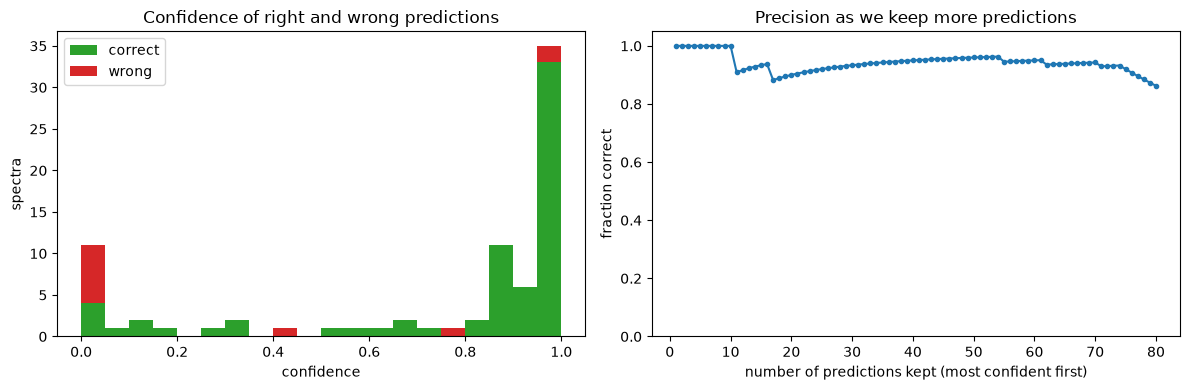

confidence >= 0.5: 61 predictions, 95% correct
confidence >= 0.8: 54 predictions, 96% correct
confidence >= 0.9: 41 predictions, 95% correct


In [15]:
k = known.sort_values("confidence", ascending=False).reset_index(drop=True)
k["kept"] = np.arange(1, len(k) + 1)
k["precision"] = k.correct.cumsum() / k.kept

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist([k.confidence[k.correct == 1], k.confidence[k.correct == 0]], bins=20, stacked=True,
           label=["correct", "wrong"], color=["tab:green", "tab:red"])
ax[0].set(xlabel="confidence", ylabel="spectra", title="Confidence of right and wrong predictions")
ax[0].legend()
ax[1].plot(k.kept, k.precision, marker=".")
ax[1].set(xlabel="number of predictions kept (most confident first)", ylabel="fraction correct",
          ylim=(0, 1.05), title="Precision as we keep more predictions")
plt.tight_layout(); plt.show()

for thr in (0.5, 0.8, 0.9):
    s = k[k.confidence >= thr]
    print(f"confidence >= {thr}: {len(s)} predictions, {s.correct.mean():.0%} correct")

## Which residues is the model unsure about?

InstaNovo also gives a confidence for **each residue**. Below: a correct prediction, a wrong one,
and the most confident wrong one.

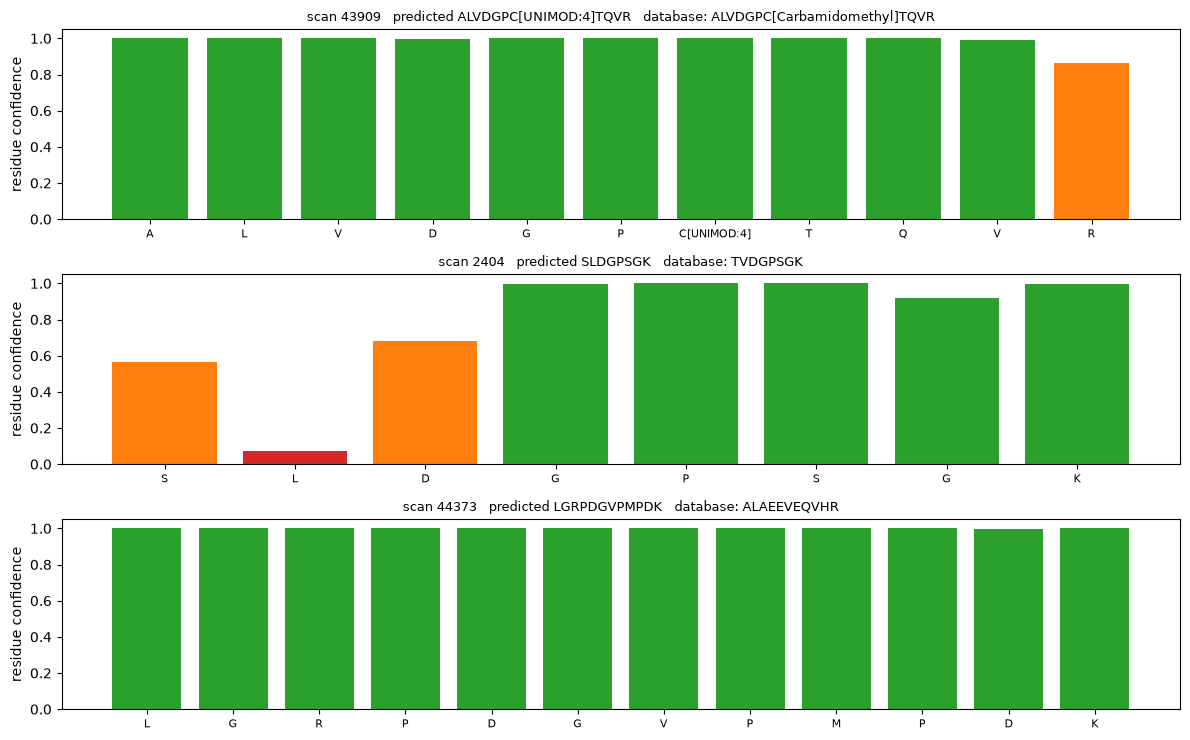

In [16]:
import ast

def residue_confidence(row, ax):
    tokens = [t.strip() for t in str(row.predictions_tokenised).split(",")]
    p = np.exp(np.array(ast.literal_eval(row.token_log_probs), float))[:len(tokens)]
    ax.bar(range(len(tokens)), p, color=["tab:green" if v > 0.9 else "tab:orange" if v > 0.5 else "tab:red" for v in p])
    ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_ylabel("residue confidence")
    truth = row.msgf_peptide if isinstance(row.msgf_peptide, str) else "no database answer"
    ax.set_title(f"scan {row.scan}   predicted {row.predictions}   database: {truth}", fontsize=9)

def weakest(row):
    return np.exp(np.array(ast.literal_eval(row.token_log_probs), float)).min()

wrong_all = known[known.correct == 0].copy()
wrong_all["weakest"] = wrong_all.apply(weakest, axis=1)
right = known[known.correct == 1].sort_values("confidence").iloc[len(known) // 4]      # a typical correct one
dip = wrong_all[wrong_all.confidence > 0.01].sort_values("weakest").iloc[0]         # wrong, with a clear weak spot
overconfident = wrong_all.sort_values("confidence").iloc[-1]                         # the most confident wrong one
fig, ax = plt.subplots(3, 1, figsize=(12, 7.5))
for a, row in zip(ax, (right, dip, overconfident)):
    residue_confidence(row, a)
plt.tight_layout(); plt.show()

Often the error is visible as a weak residue. The last example is different: the prediction disagrees
with the database search although every residue is near 1.0. A model's confidence is not a calibrated
probability, which is why de novo results need a separate step for calibration and false discovery
rate control (for example [winnow](https://github.com/instadeepai/winnow)).

## The spectra the database search could not explain

20 of the 100 spectra got **no** confident answer from the database search. Some are noise. But look at
what InstaNovo says about the rest.

In [17]:
unknown = preds[preds.msgf_peptide.isna()].sort_values("confidence", ascending=False)
unknown[["scan", "predictions", "confidence", "delta_mass_ppm"]].head(10)

,scan,predictions,confidence,delta_mass_ppm
61,42102,[UNIMOD:5]-AVTEQGHELSNEER,0.999948,3.169636
42,77439,[UNIMOD:385]-QQISLATQMVR,0.999387,3.084002
65,57085,ITDNMFC[UNIMOD:4]AGYKPGEGK,0.999226,3.830306
88,31984,DAEDAVYGR,0.997562,118.477004
11,11826,KYEEVAR,0.969789,18.347706
22,73662,ASIQEC[UNIMOD:4]ILPDSPLYHNK,0.956431,22.262524
69,74962,ELSPDIAHLASLK,0.893238,283.929201
10,28234,ETSSDVALASH,0.782784,4.885825
63,46695,EFVLDSR,0.059093,29.361063
64,23273,KSPQPTQDDLVK,0.048018,14540.423364


**Question 3.6** Look at the confident predictions among these 20. Several carry a modification. Which
modifications are they (use the UNIMOD list above)? Which of them could have been *created during
sample preparation* rather than in the cell? Why would the database search have missed them?

**Question 3.7** `delta_mass_ppm` is how far the measured precursor mass is from the mass of the
predicted peptide. InstaNovo already allows for the instrument having picked the second isotope peak
(1.003 Da heavier) instead of the first. Most confident predictions are within 5 ppm, but two are off by
more than 100 ppm. How many daltons is 100 ppm for a 1000 Da peptide? Would you report these two?

**Question 3.8** Find the most confident prediction that *disagrees* with the database search. Which
of the two answers would you believe, and what would you check to decide?

---
## What to take away

1. A fragment spectrum encodes the sequence as **mass differences** between b ions and between y ions.
2. Some things can never be resolved from mass alone: **I/L**, and pairs such as **GG/N** and
   **AG/Q** when the fragment between them is missing.
3. A graph algorithm can read clean spectra, but real spectra (noise, missing and multiply charged
   fragments) defeat simple scoring.
4. A learned model reads real spectra far better and reports a **confidence** that tracks accuracy,
   though not perfectly.
5. De novo sequencing needs no database, so it finds what a database search cannot: unexpected
   modifications, sample-preparation artefacts, and peptides that are not in your database at all.